# Formula 1 Winners Prediction (2014 to 2021)

Can we predict the winner of a Grand Prix of the hybrid era (2014 to 2021) with only what is known **before the start**: the grid, qualifying, the championship so far and recent form?

Only one driver out of about twenty wins each race, so about 95% of the rows are "did not win". A model that always says "no" is 95% accurate and useless. This notebook therefore judges models on two things:

1. **Per driver**: precision, recall and F1-score on the winner class.
2. **Per race**: for each Grand Prix, the driver with the highest predicted probability is the predicted winner. How many races does the model call right, compared with the simplest rule, "the pole sitter wins"?

Train: seasons 2014 to 2020. Test: 2021, never seen during training or tuning.

## 1) Data collection

The original Ergast API was shut down; [Jolpica](https://github.com/jolpica/jolpica-f1) serves the same data at the same paths. Every response is cached in `data/raw/`, so the notebook can be re-run without calling the API again. The API allows a few requests per second and a few hundred per hour, so calls are spaced out.

Qualifying times now come from the API's qualifying endpoint instead of scraping Formula1.com: the site changed its pages and the scraper no longer worked.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)

API = 'https://api.jolpi.ca/ergast/f1'
RAW = Path('data/raw')
RAW.mkdir(parents=True, exist_ok=True)
SEASONS = range(2014, 2022)


def get(path, **params):
    """GET an API path, cached on disk, retried politely when rate-limited."""
    key = path.strip('/').replace('/', '_') + ''.join(f'_{k}{v}' for k, v in sorted(params.items())) + '.json'
    cached = RAW / key
    if cached.exists():
        return json.loads(cached.read_text())
    for attempt in range(6):
        r = requests.get(f'{API}/{path}.json', params=params, timeout=30)
        if r.status_code == 429:
            time.sleep(10 * (attempt + 1))
            continue
        r.raise_for_status()
        cached.write_text(r.text)
        time.sleep(0.35)
        return r.json()
    raise RuntimeError(f'Rate-limited too many times on {path}')


def get_all_races(path):
    """Follow the API's pagination and return every race of a paged endpoint."""
    races, offset = {}, 0
    while True:
        data = get(path, limit=100, offset=offset)['MRData']
        for race in data['RaceTable']['Races']:
            key = int(race['round'])
            if key in races:  # a race split across two pages
                for field in ('Results', 'QualifyingResults'):
                    races[key].setdefault(field, []).extend(race.get(field, []))
            else:
                races[key] = race
        offset += int(data['limit'])
        if offset >= int(data['total']):
            return list(races.values())

In [2]:
races, results, qualifying = [], [], []

for year in SEASONS:
    for race in get(f'{year}')['MRData']['RaceTable']['Races']:
        races.append({
            'season': year,
            'round': int(race['round']),
            'circuit_id': race['Circuit']['circuitId'],
            'country': race['Circuit']['Location']['country'],
            'date': race['date'],
        })

    for race in get_all_races(f'{year}/results'):
        for res in race['Results']:
            results.append({
                'season': year,
                'round': int(race['round']),
                'driver': res['Driver']['driverId'],
                'date_of_birth': res['Driver']['dateOfBirth'],
                'constructor': res['Constructor']['constructorId'],
                'grid': int(res['grid']),
                'position': int(res['position']),
                'status': res['status'],
            })

    for race in get_all_races(f'{year}/qualifying'):
        for q in race['QualifyingResults']:
            qualifying.append({
                'season': year,
                'round': int(race['round']),
                'driver': q['Driver']['driverId'],
                'q1': q.get('Q1'), 'q2': q.get('Q2'), 'q3': q.get('Q3'),
            })

races = pd.DataFrame(races)
results = pd.DataFrame(results)
qualifying = pd.DataFrame(qualifying)
print(len(races), 'races |', len(results), 'driver results |', len(qualifying), 'qualifying rows')

160 races | 3267 driver results | 3251 qualifying rows


**Championship standings before each race.** The standings published after round *n* are what is known before round *n + 1*. Using the standings of the same round would leak the result of the race we are trying to predict, so each race gets the standings of the previous round (zero points before round 1).

In [3]:
standings = []
for year in SEASONS:
    for rnd in range(1, int(races[races.season == year]['round'].max()) + 1):
        lists = get(f'{year}/{rnd}/driverStandings')['MRData']['StandingsTable']['StandingsLists']
        for s in lists[0]['DriverStandings'] if lists else []:
            standings.append({
                'season': year,
                'round': rnd + 1,  # known before the next race
                'driver': s['Driver']['driverId'],
                'points_before': float(s['points']),
                'wins_before': int(s['wins']),
                'standing_before': float(s['position']) if 'position' in s else np.nan,
            })
standings = pd.DataFrame(standings)
standings.head()

,season,round,driver,points_before,wins_before,standing_before
0,2014,2,rosberg,25.0,1,1.0
1,2014,2,kevin_magnussen,18.0,0,2.0
2,2014,2,button,15.0,0,3.0
3,2014,2,alonso,12.0,0,4.0
4,2014,2,bottas,10.0,0,5.0


## 2) Preparation

**Qualifying gap.** The original notebook sorted drivers by grid position and summed the differences between consecutive times. The grid is not the qualifying order (penalties, pit-lane starts), so gaps could come out wrong or negative. Here each driver's gap is their best qualifying lap compared with the fastest lap of that qualifying, in percent, so it is comparable between short and long circuits.

**Merging.** Tables are joined on season, round **and driver**. The original joined qualifying on grid position, which attaches a driver's qualifying time to someone else whenever the grid differs from the qualifying order.

In [4]:
def lap_seconds(t):
    if not isinstance(t, str) or ':' not in t:
        return np.nan
    minutes, seconds = t.split(':')
    return 60 * float(minutes) + float(seconds)

for col in ('q1', 'q2', 'q3'):
    qualifying[col + '_s'] = qualifying[col].map(lap_seconds)
qualifying['best_quali'] = qualifying[['q1_s', 'q2_s', 'q3_s']].min(axis=1)
pole = qualifying.groupby(['season', 'round'])['best_quali'].transform('min')
qualifying['quali_gap_pct'] = 100 * (qualifying['best_quali'] - pole) / pole

df = (results
      .merge(races, on=['season', 'round'], how='left')
      .merge(qualifying[['season', 'round', 'driver', 'quali_gap_pct']], on=['season', 'round', 'driver'], how='left')
      .merge(standings, on=['season', 'round', 'driver'], how='left'))

df['date'] = pd.to_datetime(df['date'])
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'])
df['age'] = (df['date'] - df['date_of_birth']).dt.days / 365.25
df = df.sort_values(['date', 'position']).reset_index(drop=True)

# Before round 1, and for a driver's first race, there is no standing yet.
df[['points_before', 'wins_before']] = df[['points_before', 'wins_before']].fillna(0)
df['standing_before'] = df['standing_before'].fillna(df['standing_before'].max())

# Grid 0 means a pit-lane start: the back of the grid.
df['grid'] = df['grid'].replace(0, 25)

# No qualifying time (did not set one, or excluded): treat as the slowest of the race.
worst = df.groupby(['season', 'round'])['quali_gap_pct'].transform('max')
df['quali_gap_pct'] = df['quali_gap_pct'].fillna(worst)
# A race with no qualifying times at all in the source (2020 Sakhir GP):
# use the median gap seen from the same grid slot in other races.
by_grid = df.groupby('grid')['quali_gap_pct'].median()
missing = df['quali_gap_pct'].isna()
print(f'{missing.sum()} rows without any qualifying time, filled from their grid slot')
df.loc[missing, 'quali_gap_pct'] = df.loc[missing, 'grid'].map(by_grid)

df['target'] = (df['position'] == 1).astype(int)
print(df.shape, '| winners per race:', df.groupby(['season', 'round'])['target'].sum().value_counts().to_dict())
df.head()

20 rows without any qualifying time, filled from their grid slot
(3267, 17) | winners per race: {1: 160}


,season,round,driver,date_of_birth,constructor,grid,position,status,circuit_id,country,date,quali_gap_pct,points_before,wins_before,standing_before,age,target
0,2014,1,rosberg,1985-06-27,mercedes,3,1,Finished,albert_park,Australia,2014-03-16,1.970807,0.0,0.0,24.0,28.717317,1
1,2014,1,kevin_magnussen,1992-10-05,mclaren,4,2,Finished,albert_park,Australia,2014-03-16,0.191683,0.0,0.0,24.0,21.442847,0
2,2014,1,button,1980-01-19,mclaren,10,3,Finished,albert_park,Australia,2014-03-16,0.684109,0.0,0.0,24.0,34.154689,0
3,2014,1,alonso,1981-07-29,ferrari,5,4,Finished,albert_park,Australia,2014-03-16,0.675296,0.0,0.0,24.0,32.629706,0
4,2014,1,bottas,1989-08-28,williams,15,5,Finished,albert_park,Australia,2014-03-16,0.909942,0.0,0.0,24.0,24.547570,0


**Recent form.** Rolling averages over the driver's **three previous races** (`closed='left'` excludes the current race). Finishing position counts a retirement as 20th, and the finish rate is the share of those races the driver finished.

**Team form** replaces the original "Top Team" flag. That flag was chosen by looking at the whole period, including the 2021 test season, which tells the model something it could not know. Team form is the team's best finishing position in its three previous races.

Fields that are only known **after** the race are not used as inputs: the original model used `status_id` (did the driver finish?), and a driver who did not finish cannot win, so the model was partly reading the answer. The overall win ratio per driver was also computed over every season including 2021.

In [5]:
df['finished'] = df['status'].str.match(r'^(Finished|\+\d+ Laps?)$').astype(int)
df['finish_pos'] = np.where(df['finished'] == 1, df['position'], 20)

def rolling_prev(group, col, n=3):
    return group[col].transform(lambda s: s.rolling(n, min_periods=1, closed='left').mean())

by_driver = df.groupby('driver', group_keys=False)
df['grid_form'] = rolling_prev(by_driver, 'grid')
df['quali_form'] = rolling_prev(by_driver, 'quali_gap_pct')
df['finish_form'] = rolling_prev(by_driver, 'finish_pos')
df['finish_rate'] = rolling_prev(by_driver, 'finished')

team_best = (df.groupby(['constructor', 'date'])['finish_pos'].min()
               .groupby(level='constructor', group_keys=False)
               .apply(lambda s: s.rolling(3, min_periods=1, closed='left').mean())
               .rename('team_form').reset_index())
df = df.merge(team_best, on=['constructor', 'date'], how='left')

form_cols = ['grid_form', 'quali_form', 'finish_form', 'finish_rate', 'team_form']
before = len(df)
df = df.dropna(subset=form_cols).reset_index(drop=True)
print(f'{before - len(df)} rows dropped: a driver or team with no previous race to compute form from')

65 rows dropped: a driver or team with no previous race to compute form from


## 3) A first look

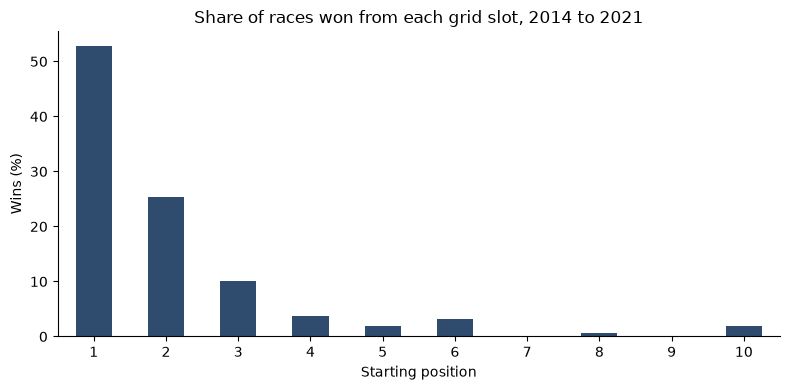

Pole sitter won 53% of races


In [6]:
win_by_grid = df[df.grid <= 10].groupby('grid')['target'].mean() * 100
ax = win_by_grid.plot(kind='bar', color='#2f4b6e', figsize=(8, 4))
ax.set_xlabel('Starting position')
ax.set_ylabel('Wins (%)')
ax.set_title('Share of races won from each grid slot, 2014 to 2021')
ax.tick_params(axis='x', rotation=0)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
Path('figures').mkdir(exist_ok=True)
plt.savefig('figures/win_rate_by_grid.png', dpi=150)
plt.show()
print(f"Pole sitter won {win_by_grid.loc[1]:.0f}% of races")

**Championship points per season.** The original chart added up the standings of every race, and standings are already cumulative, so the totals went past 4,000 points. A season's total is the standing after its last race. To keep the chart readable, only the drivers who finished in the top 3 at least once are drawn, each with its name at the end of its line.

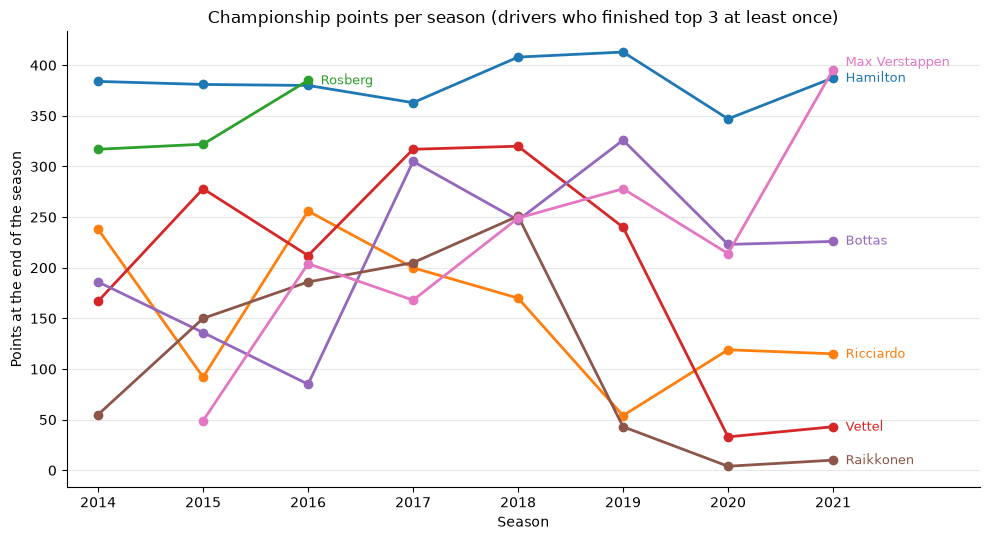

In [7]:
final_points = standings.groupby(['season', 'driver'])['points_before'].max().reset_index()
final_points['rank'] = final_points.groupby('season')['points_before'].rank(ascending=False)
top_drivers = final_points[final_points['rank'] <= 3]['driver'].unique()

fig, ax = plt.subplots(figsize=(10, 5.5))
labels = []
for driver in top_drivers:
    one = final_points[final_points['driver'] == driver]
    line, = ax.plot(one['season'], one['points_before'], marker='o', linewidth=2)
    last = one.iloc[-1]
    labels.append([last['season'], last['points_before'], driver.replace('_', ' ').title(), line.get_color()])

# Names at the end of each line, pushed apart when two lines end close together
labels.sort(key=lambda l: (l[0], l[1]))
for i in range(1, len(labels)):
    if labels[i][0] == labels[i - 1][0] and labels[i][1] - labels[i - 1][1] < 15:
        labels[i][1] = labels[i - 1][1] + 15
for season, points, name, color in labels:
    ax.text(season + 0.12, points, name, va='center', fontsize=9, color=color)

ax.set_title('Championship points per season (drivers who finished top 3 at least once)')
ax.set_xlabel('Season')
ax.set_ylabel('Points at the end of the season')
ax.set_xticks(list(SEASONS))
ax.set_xlim(2013.7, 2022.4)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figures/points_per_season.png', dpi=150)
plt.show()

**Does pole position win the race?** The original chart computed a correlation per circuit on a few rows each, which is hard to read and unstable. A simpler question gives a clearer answer: at each circuit, in how many races did the pole sitter win? Only circuits with at least 5 races are shown.

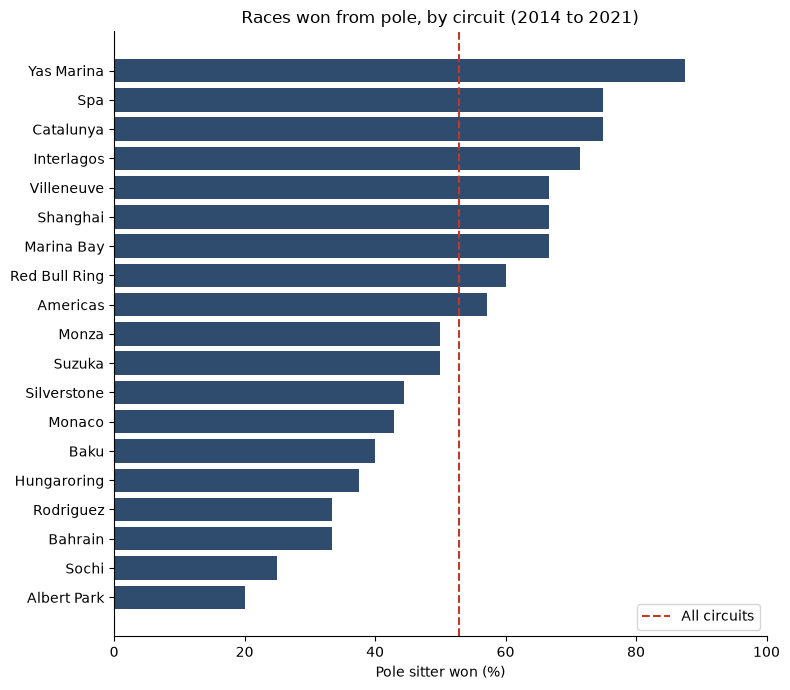

In [8]:
poles = df[df['grid'] == 1]
by_circuit = poles.groupby('circuit_id')['target'].agg(['mean', 'count'])
by_circuit = by_circuit[by_circuit['count'] >= 5].sort_values('mean')

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(by_circuit.index.str.replace('_', ' ').str.title(), by_circuit['mean'] * 100, color='#2f4b6e')
ax.axvline(poles['target'].mean() * 100, color='#c0392b', linestyle='--', label='All circuits')
ax.set_title('Races won from pole, by circuit (2014 to 2021)')
ax.set_xlabel('Pole sitter won (%)')
ax.set_xlim(0, 100)
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figures/pole_wins_by_circuit.png', dpi=150)
plt.show()

## 4) Models

**Inputs.** Only what is known before the start. Driver and circuit IDs are left out: their numeric codes carry no order, and an ID mostly lets a model memorise who won in the past.

**Tuning without touching 2021.** The original notebook picked hyperparameters by their score on the 2021 test set, which makes the test score optimistic, and used shuffled 5-fold cross-validation, which lets a model train on races that come after the ones it is validated on. Here, tuning uses only 2014 to 2020 with forward-in-time folds (train up to 2017, validate on 2018; up to 2018, validate on 2019; up to 2019, validate on 2020), scored on average precision, which suits a rare positive class.

In [9]:
from sklearn.base import clone
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier

FEATURES = ['grid', 'quali_gap_pct', 'points_before', 'wins_before', 'standing_before', 'age'] + form_cols

train = df[df.season <= 2020].reset_index(drop=True)
test = df[df.season == 2021].reset_index(drop=True)
X_train, y_train = train[FEATURES], train['target']
X_test, y_test = test[FEATURES], test['target']

season_folds = [
    (np.where(train.season <= last)[0], np.where(train.season == last + 1)[0])
    for last in (2017, 2018, 2019)
]
print(f'Train: {len(train)} rows, {y_train.sum()} wins | Test 2021: {len(test)} rows, {y_test.sum()} wins')

Train: 2769 rows, 137 wins | Test 2021: 433 rows, 22 wins


In [10]:
candidates = {
    'Logistic regression': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                            {'logisticregression__C': [0.01, 0.1, 1, 10]}),
    'Random Forest': (RandomForestClassifier(random_state=0, n_jobs=-1),
                      {'n_estimators': [200, 400], 'max_depth': [3, 5, 7], 'min_samples_leaf': [1, 5, 10]}),
    'Gradient Boosting': (GradientBoostingClassifier(random_state=0),
                          {'n_estimators': [100, 200], 'max_depth': [2, 3], 'learning_rate': [0.05, 0.1]}),
    'AdaBoost': (AdaBoostClassifier(random_state=0),
                 {'n_estimators': [100, 300], 'learning_rate': [0.1, 0.5, 1.0]}),
    'CatBoost': (CatBoostClassifier(random_seed=0, verbose=False, thread_count=-1),
                 {'iterations': [300, 600], 'depth': [3, 5], 'learning_rate': [0.03, 0.1]}),
}

tuned, validation_ap = {}, {}
for name, (model, grid) in candidates.items():
    search = GridSearchCV(model, grid, cv=season_folds, scoring='average_precision', n_jobs=1)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    validation_ap[name] = search.best_score_
    print(f'{name:20s} validation AP {search.best_score_:.3f}  {search.best_params_}')

Logistic regression  validation AP 0.492  {'logisticregression__C': 1}


Random Forest        validation AP 0.506  {'max_depth': 7, 'min_samples_leaf': 5, 'n_estimators': 200}


Gradient Boosting    validation AP 0.472  {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}


AdaBoost             validation AP 0.393  {'learning_rate': 0.1, 'n_estimators': 100}


CatBoost             validation AP 0.493  {'depth': 5, 'iterations': 300, 'learning_rate': 0.1}


## 5) Results on the 2021 season

**Per race**: the driver with the highest probability in each Grand Prix is the predicted winner. **Per driver**: a row counts as "predicted winner" when its probability is at least 0.5, as in the original notebook.

In [11]:
def race_hits(frame, scores):
    picked = frame.assign(score=scores).sort_values('score', ascending=False).groupby(['season', 'round']).head(1)
    return picked['target'].sum(), len(picked)

rows = []
hits, n_races = race_hits(test, -test['grid'])
rows.append({'Model': 'Pole sitter wins (baseline)', 'Races called': f'{hits}/{n_races}',
             'Race hit rate': hits / n_races, 'Precision': np.nan, 'Recall': np.nan, 'F1': np.nan})

for name, model in tuned.items():
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    hits, n_races = race_hits(test, proba)
    rows.append({'Model': name, 'Races called': f'{hits}/{n_races}', 'Race hit rate': hits / n_races,
                 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred)})

scores = pd.DataFrame(rows).set_index('Model')
scores.style.format({'Race hit rate': '{:.0%}', 'Precision': '{:.2f}', 'Recall': '{:.2f}', 'F1': '{:.2f}'}, na_rep='')

,Races called,Race hit rate,Precision,Recall,F1
Model,,,,,
Pole sitter wins (baseline),11/22,50%,,,
Logistic regression,12/22,55%,0.62,0.23,0.33
Random Forest,12/22,55%,0.75,0.27,0.40
Gradient Boosting,11/22,50%,0.64,0.32,0.42
AdaBoost,12/22,55%,0.00,0.00,0.00
CatBoost,13/22,59%,0.59,0.45,0.51


In [12]:
# The model to keep is chosen on the 2018 to 2020 validation folds, not on 2021.
best_name = max(validation_ap, key=validation_ap.get)
best = tuned[best_name]
pred = (best.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
print(f'Kept model (best validation average precision): {best_name}')
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, digits=2))

Kept model (best validation average precision): Random Forest
[[409   2]
 [ 16   6]]


              precision    recall  f1-score   support

           0       0.96      1.00      0.98       411
           1       0.75      0.27      0.40        22

    accuracy                           0.96       433
   macro avg       0.86      0.63      0.69       433
weighted avg       0.95      0.96      0.95       433



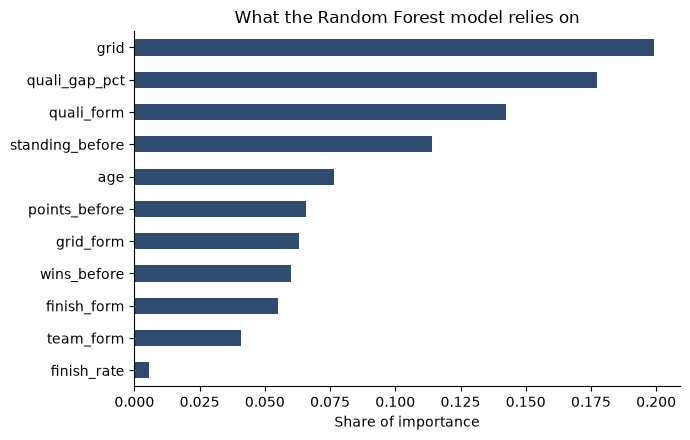

In [13]:
importance = None
if hasattr(best, 'feature_importances_'):
    importance = pd.Series(best.feature_importances_, index=FEATURES)
elif hasattr(best, 'named_steps'):
    importance = pd.Series(np.abs(best.named_steps['logisticregression'].coef_[0]), index=FEATURES)

ax = (importance / importance.sum()).sort_values().plot(kind='barh', color='#2f4b6e', figsize=(7, 4.5))
ax.set_title(f'What the {best_name} model relies on')
ax.set_xlabel('Share of importance')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('figures/feature_importance.png', dpi=150)
plt.show()

In [14]:
proba = best.predict_proba(X_test)[:, 1]
calls = (test.assign(proba=proba)
             .sort_values('proba', ascending=False)
             .groupby(['round'], as_index=False).head(1)
             .merge(test[test.target == 1][['round', 'driver']].rename(columns={'driver': 'actual_winner'}), on='round')
             .sort_values('round')[['round', 'circuit_id', 'driver', 'grid', 'proba', 'actual_winner']]
             .rename(columns={'driver': 'predicted_winner'}))
calls['correct'] = calls['predicted_winner'] == calls['actual_winner']
calls.style.format({'proba': '{:.2f}'})

,round,circuit_id,predicted_winner,grid,proba,actual_winner,correct
10,1,bahrain,max_verstappen,1,0.46,hamilton,False
3,2,imola,hamilton,1,0.66,max_verstappen,False
5,3,portimao,hamilton,2,0.56,hamilton,True
1,4,catalunya,hamilton,1,0.70,hamilton,True
21,5,monaco,leclerc,1,0.30,max_verstappen,False
18,6,baku,hamilton,2,0.33,perez,False
9,7,ricard,max_verstappen,1,0.47,max_verstappen,True
13,8,red_bull_ring,max_verstappen,1,0.43,max_verstappen,True
14,9,red_bull_ring,max_verstappen,1,0.36,max_verstappen,True
8,10,silverstone,hamilton,2,0.48,hamilton,True


## 6) Conclusions

- **The pole sitter is a strong baseline.** From 2014 to 2021 the pole sitter won 53% of races, and 11 of the 22 races of 2021. Any model has to beat that rule to be worth anything.
- **The kept model (Random Forest, chosen on the 2018 to 2020 validation seasons) calls 12 of 22 races in 2021**, one more than the pole-sitter rule. Per driver, when it gives a probability of 0.5 or more it is right 75% of the time (precision 0.75), but it only reaches that level of confidence for 6 of the 22 winners (recall 0.27).
- CatBoost happened to do best on 2021 (13 of 22 races, F1 0.51), but it was not the best on validation, so keeping it would mean choosing on the test season.
- **What the model relies on**: grid position and qualifying gap first, then recent qualifying form and the championship position. Pace over one lap, and how it has evolved over the last races, says the most.
- **Accuracy is not a useful figure here**: it stays around 96% for every model, including one that never predicts a winner (AdaBoost at the 0.5 threshold).
- 2021 is a hard test season: the closest title fight of the period, and races decided by events no pre-race data can see (Hungary, Monza, Baku, Istanbul).

**Corrections compared with the first version of this notebook**
- Data source moved from the closed Ergast API and a Formula1.com scraper that no longer worked to Jolpica, with a disk cache.
- Qualifying joined by driver instead of grid slot, and the gap computed against the pole time instead of a cumulative sum ordered by grid.
- Inputs known only after the race removed: `status_id` (did the driver finish) and a win ratio computed over every season including 2021. "Top Team", chosen by looking at the whole period, replaced by a team-form feature.
- Hyperparameters tuned on past seasons with forward-in-time folds, never on the test season, scored on average precision instead of accuracy.
- Per-race evaluation and a pole-sitter baseline added; the classification report now matches the model it describes.
- Cells that failed when run in order fixed: undefined `accuracy_score` and `f1_preds`, `teams_id` vs `team_id`, a column dropped twice, `driver_age` and `target` used before they existed, `loss='deviance'` removed from scikit-learn, unused FastF1 import removed. XGBoost was left out of the comparison.